In [19]:
from qiskit import *
from qiskit.visualization import plot_histogram, array_to_latex
%matplotlib inline
from qiskit.providers.basic_provider import BasicProvider


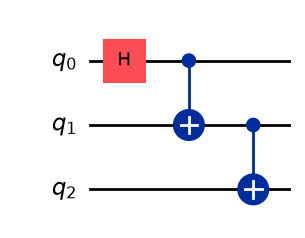

In [20]:
circuit = QuantumCircuit(3)

# Step 1: Create superposition on qubit 0
circuit.h(0)

# Step 2: Entangle qubit 0 with qubit 1
circuit.cx(0, 1)

# Step 3: Entangle qubit 1 with qubit 2
circuit.cx(1, 2)

circuit.draw(output='mpl');

In [21]:
# UPDATE: Code updated after recording to resolve breaking changes from Qiskit 1.0
circuit.remove_final_measurements()  # no measurements allowed
from qiskit.quantum_info import Statevector
statevector = Statevector(circuit)
array_to_latex(statevector, prefix="\\text{statevector = }\n")

<IPython.core.display.Latex object>

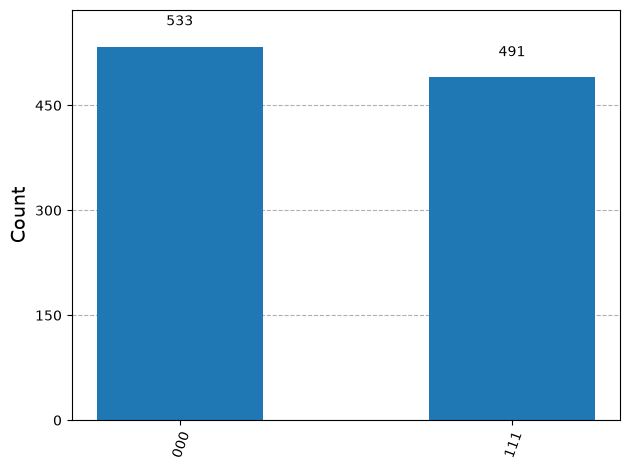

In [22]:
circuit.measure_all()

# UPDATE: Code updated after recording to resolve breaking changes from Qiskit 1.0
simulator = BasicProvider().get_backend('basic_simulator')
compiled_circuit = transpile(circuit, simulator)
result = simulator.run(compiled_circuit).result()
plot_histogram(result.get_counts());